# DATA 621 - Homework 02: Classification Metrics

## Project objective

This project evaluates an already scored binary classifier using the supplied actual labels, predicted labels, and predicted probabilities. The goal is to calculate and interpret threshold-based classification metrics and probability-based ROC/AUC, then verify the calculations with `scikit-learn`. Model training is outside the scope of this assignment because the provided data already contains the model's outputs. Class `1` is treated as the positive class throughout.


## Data Loading, Inspection and Confusion Matrix

### Data Loading and Inspection
To complete this assignment, the dataset was first uploaded to the group GitHub repository and then loaded directly from the raw GitHub URL using `pandas`. By using `pandas.read_csv()` with the raw GitHub URL, it ensures the notebook is 100% reproducible without requiring local file downloads.   

In [1]:
import pandas as pd
import numpy as np

# Load the dataset directly from the raw GitHub URL
url = "https://raw.githubusercontent.com/alinsimon/data621-data-mining/refs/heads/main/homeworks/hw02/data/classification-output-data.csv"
df = pd.read_csv(url)

# Verify dataset dimensions (181 observations, 11 columns)
print(f"Dataset shape: {df.shape}")

# Inspect the first 5 rows of the three key columns
key_cols = ['class', 'scored.class', 'scored.probability']
print(df[key_cols].head())

Dataset shape: (181, 11)
   class  scored.class  scored.probability
0      0             0            0.328452
1      0             0            0.273190
2      1             0            0.109660
3      0             0            0.055998
4      0             0            0.100491


### Confusion Matrix
The cleanest way to generate a labeled raw confusion matrix is by using `pd.crosstab()` because the order in which the arguments are passed explicitly defines what the rows and columns represent.

In [2]:
def get_confusion_matrix(data, actual_col='class', predicted_col='scored.class'):
    """
    Returns the raw confusion matrix using pandas crosstab.
    Rows (index) = Actual Class
    Columns = Predicted Class
    """
    return pd.crosstab(
        index=data[actual_col],
        columns=data[predicted_col],
        rownames=['Actual (class)'],
        colnames=['Predicted (scored.class)'],
        margins=True  # Adds row/column totals for easy verification
    )

conf_matrix = get_confusion_matrix(df)
print(conf_matrix)

Predicted (scored.class)    0   1  All
Actual (class)                        
0                         119   5  124
1                          30  27   57
All                       149  32  181


#### Confusion Matrix Explained

In the primary `pd.crosstab(df['class'], df['scored.class']` output, the rows represent the actual class (`class`), while the columns represent the predicted class (`scored.class`) at the 0.5 probability threshold. 
Row `0` contains all 124 observations that are actually negative (`class == 0`) and Row `1` contains all 57 observations that are actually positive (`class == 1`).
Column `0` contains all 149 observations predicted to be negative (`scored.class == 0`), and Column `1` contains all 32 observations predicted to be positive (`scored.class == 1`).

*Breakdown of Quadrants (N = 181)*

| Metric | Cell Coordinate (Actual, Predicted) | Count | Percentage | Meaning |
|:---|:---|---:|---:|:---|
| **True Negatives ($TN$)** | `(0, 0)` — Top-Left | **119** | 65.75% | The actual class was `0` and the model correctly predicted `0`. |
| **False Positives ($FP$)** | `(0, 1)` — Top-Right | **5** | 2.76% | The actual class was `0`, but the model incorrectly predicted `1` (Type I Error). |
| **False Negatives ($FN$)** | `(1, 0)` — Bottom-Left | **30** | 16.57% | The actual class was `1`, but the model incorrectly predicted `0` (Type II Error). |
| **True Positives ($TP$)** | `(1, 1)` — Bottom-Right | **27** | 14.92% | The actual class was `1` and the model correctly predicted `1`. |

Out of 181 total observations, the model classified $119 + 27 = 146$ correctly ($80.66\%$ accuracy) and misclassified $5 + 30 = 35$ observations ($19.34\%$ error rate).The errors are heavily skewed toward False Negatives (30) compared to False Positives (5), meaning the model is conservative at the 0.5 threshold—when it predicts a positive case (1), it is usually right, but it misses more than half of the actual positive cases ($27 / 57 \approx 47.37\%$ sensitivity).

## Implement and Interpret the Classification Metrics

Following Kuhn & Johnson, *Applied Predictive Modeling* (Chapter 11), each metric is implemented from the confusion-matrix counts with class `1` as the positive (event) class. Each function takes the data frame and returns a single value, then is checked against `scikit-learn`.

In [3]:
def _counts(data, actual_col='class', predicted_col='scored.class'):
    a, p = data[actual_col], data[predicted_col]
    tp = int(((a == 1) & (p == 1)).sum())
    tn = int(((a == 0) & (p == 0)).sum())
    fp = int(((a == 0) & (p == 1)).sum())
    fn = int(((a == 1) & (p == 0)).sum())
    return tp, tn, fp, fn

def accuracy(data, actual_col='class', predicted_col='scored.class'):
    tp, tn, fp, fn = _counts(data, actual_col, predicted_col)
    return (tp + tn) / (tp + tn + fp + fn)

def classification_error_rate(data, actual_col='class', predicted_col='scored.class'):
    tp, tn, fp, fn = _counts(data, actual_col, predicted_col)
    return (fp + fn) / (tp + tn + fp + fn)

def precision(data, actual_col='class', predicted_col='scored.class'):
    tp, tn, fp, fn = _counts(data, actual_col, predicted_col)
    return tp / (tp + fp)

def sensitivity(data, actual_col='class', predicted_col='scored.class'):
    tp, tn, fp, fn = _counts(data, actual_col, predicted_col)
    return tp / (tp + fn)

def specificity(data, actual_col='class', predicted_col='scored.class'):
    tp, tn, fp, fn = _counts(data, actual_col, predicted_col)
    return tn / (tn + fp)

def f1_score_manual(data, actual_col='class', predicted_col='scored.class'):
    p = precision(data, actual_col, predicted_col)
    s = sensitivity(data, actual_col, predicted_col)
    return 2 * p * s / (p + s)

metrics = pd.Series({
    'Accuracy': accuracy(df),
    'Classification error rate': classification_error_rate(df),
    'Precision': precision(df),
    'Sensitivity (recall)': sensitivity(df),
    'Specificity': specificity(df),
    'F1 score': f1_score_manual(df),
}, name='Value')
print(metrics.round(4))
print('Accuracy + error rate =', accuracy(df) + classification_error_rate(df))

Accuracy                     0.8066
Classification error rate    0.1934
Precision                    0.8438
Sensitivity (recall)         0.4737
Specificity                  0.9597
F1 score                     0.6067
Name: Value, dtype: float64
Accuracy + error rate = 1.0


### F1 score bounds

$F_1 = \dfrac{2 \cdot \text{precision} \cdot \text{sensitivity}}{\text{precision} + \text{sensitivity}}$. Both precision and sensitivity lie in $[0, 1]$. If either is $0$ then $F_1 = 0$, and if both are $1$ then $F_1 = 1$. Because $F_1$ is the harmonic mean of the two, it never exceeds the larger of them, so $0 \le F_1 \le 1$. It reaches $0$ only when there are no true positives, and $1$ only when there are no false positives and no false negatives. The code below checks this over a grid of precision and sensitivity values.

In [4]:
grid = np.linspace(0.001, 1, 200)
P, S = np.meshgrid(grid, grid)
F = 2 * P * S / (P + S)
print(f"min F1 over grid = {F.min():.4f}, max F1 over grid = {F.max():.4f}")

min F1 over grid = 0.0010, max F1 over grid = 1.0000


## ROC Curve and AUC

The ROC (receiver operating characteristic) curve shows how the classifier trades sensitivity against specificity as the cut-off on `scored.probability` changes. For each threshold $t$, an observation is predicted positive when `scored.probability` $\ge t$, and two rates are computed from the resulting confusion matrix:

- **True positive rate (sensitivity):** $TPR = \dfrac{TP}{TP + FN}$
- **False positive rate (1 − specificity):** $FPR = \dfrac{FP}{FP + TN}$

Each threshold gives one $(FPR, TPR)$ point. A threshold of 0 labels everything positive, giving the point $(1, 1)$. A threshold above the largest probability labels everything negative, giving $(0, 0)$. The curve joins these points.

The AUC (area under the curve) is computed with the trapezoidal rule: between consecutive points, the area is the width $\Delta FPR$ times the average height $\tfrac{1}{2}(TPR_i + TPR_{i+1})$, and these strips are summed. An AUC of 0.5 corresponds to random guessing (the diagonal) and 1.0 to perfect separation.

As recommended in the assignment, the function's default is a grid of thresholds from 0 to 1 in steps of 0.01. It can also use every distinct predicted probability as a threshold (`thresholds="exact"`), which traces the full step-shaped curve and gives the exact AUC. The function returns a dictionary containing the plot, the AUC, and the table of rates at each threshold.

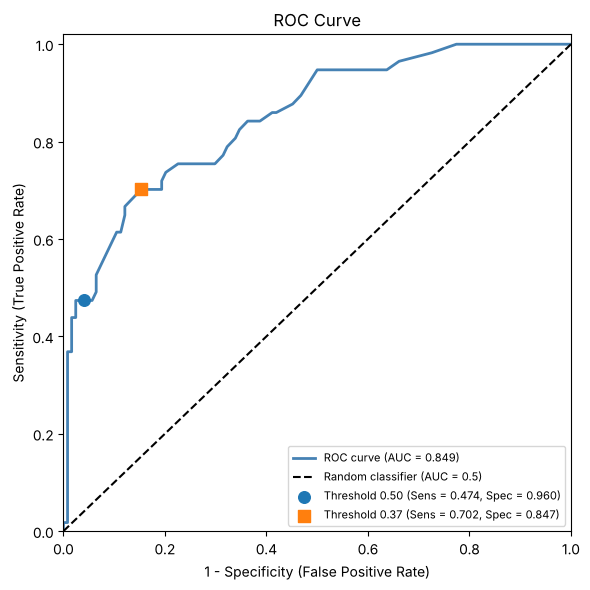

AUC (0.01 threshold grid)          = 0.8489
AUC (every distinct probability)  = 0.8503
Best threshold by Youden's J      = 0.37 (J = 0.5485)

Sensitivity and specificity at selected thresholds:
 threshold  TPR (sensitivity)  FPR (1 - specificity)  specificity
      0.20             0.8596                 0.4113       0.5887
      0.30             0.7544                 0.2500       0.7500
      0.37             0.7018                 0.1532       0.8468
      0.40             0.6491                 0.1210       0.8790
      0.50             0.4737                 0.0403       0.9597


In [5]:
import matplotlib.pyplot as plt

def roc_curve_manual(data, actual_col='class', prob_col='scored.probability',
                     thresholds=None, mark_thresholds=(0.5,)):
    """
    Build an ROC curve from scratch and compute its AUC with the trapezoidal rule.

    Parameters
    ----------
    data : DataFrame containing the actual class (0/1) and the predicted probability
    thresholds : None  -> grid from 0 to 1 in steps of 0.01 (assignment default)
                 "exact" -> every distinct predicted probability (full-resolution curve)
                 array -> any custom set of thresholds
    mark_thresholds : thresholds to highlight on the plot (e.g., the default 0.5 cut-off)

    Returns
    -------
    dict with keys:
        'plot'      : the matplotlib Figure of the ROC curve
        'auc'       : area under the curve (float)
        'roc_table' : DataFrame of threshold, TPR (sensitivity), FPR, specificity
    """
    actual = data[actual_col].to_numpy()
    prob = data[prob_col].to_numpy()
    n_pos = (actual == 1).sum()
    n_neg = (actual == 0).sum()

    # Choose the thresholds to sweep
    if thresholds is None:
        thresholds = np.round(np.arange(0, 1.01, 0.01), 2)
    elif isinstance(thresholds, str) and thresholds == "exact":
        # Every distinct probability, plus 0 and a value above the maximum,
        # so the curve always runs from (0, 0) to (1, 1)
        thresholds = np.unique(np.concatenate([[0.0], prob, [np.inf]]))
    thresholds = np.sort(np.asarray(thresholds, dtype=float))

    # Sensitivity and false positive rate at each threshold
    tpr = np.array([((prob >= t) & (actual == 1)).sum() / n_pos for t in thresholds])
    fpr = np.array([((prob >= t) & (actual == 0)).sum() / n_neg for t in thresholds])

    # Order points by FPR (ties broken by TPR) and add the (0,0) end point if missing,
    # since a threshold of 1.00 can still leave a few predicted positives
    order = np.lexsort((tpr, fpr))
    fpr_sorted, tpr_sorted = fpr[order], tpr[order]
    if fpr_sorted[0] > 0 or tpr_sorted[0] > 0:
        fpr_sorted = np.insert(fpr_sorted, 0, 0.0)
        tpr_sorted = np.insert(tpr_sorted, 0, 0.0)

    # Trapezoidal rule: sum of (width x average height) over consecutive points
    auc = np.sum(np.diff(fpr_sorted) * (tpr_sorted[1:] + tpr_sorted[:-1]) / 2)

    roc_table = pd.DataFrame({
        'threshold': thresholds,
        'TPR (sensitivity)': tpr,
        'FPR (1 - specificity)': fpr,
        'specificity': 1 - fpr,
    })

    # Plot the curve, the random-classifier diagonal, and the marked thresholds
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot(fpr_sorted, tpr_sorted, color='steelblue', linewidth=2,
            label=f'ROC curve (AUC = {auc:.3f})')
    ax.plot([0, 1], [0, 1], 'k--', label='Random classifier (AUC = 0.5)')
    markers = ['o', 's', '^', 'D']
    for k, t in enumerate(mark_thresholds):
        t_tpr = ((prob >= t) & (actual == 1)).sum() / n_pos
        t_fpr = ((prob >= t) & (actual == 0)).sum() / n_neg
        ax.scatter(t_fpr, t_tpr, s=70, zorder=3, marker=markers[k % len(markers)],
                   label=f'Threshold {t:.2f} (Sens = {t_tpr:.3f}, Spec = {1 - t_fpr:.3f})')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel('1 - Specificity (False Positive Rate)')
    ax.set_ylabel('Sensitivity (True Positive Rate)')
    ax.set_title('ROC Curve')
    ax.legend(loc='lower right', fontsize=8)
    fig.tight_layout()
    plt.close(fig)  # returned in the dict; displayed explicitly below

    return {'plot': fig, 'auc': auc, 'roc_table': roc_table}


# ROC curve using the assignment's 0.01 threshold grid
roc_grid = roc_curve_manual(df)

# Threshold that maximizes Youden's J = sensitivity + specificity - 1 (Kuhn & Johnson, Ch. 11)
grid_table = roc_grid['roc_table']
youden_j = grid_table['TPR (sensitivity)'] - grid_table['FPR (1 - specificity)']
best_row = grid_table.loc[youden_j.idxmax()]
best_threshold = best_row['threshold']

# Redraw with both the default 0.5 cut-off and the Youden threshold marked
roc_grid = roc_curve_manual(df, mark_thresholds=(0.5, best_threshold))
display(roc_grid['plot'])

# Full-resolution curve using every distinct probability as a threshold
roc_exact = roc_curve_manual(df, thresholds="exact")
auc_manual = roc_exact['auc']     # exact AUC, used in the scikit-learn comparison below
fpr = roc_exact['roc_table']['FPR (1 - specificity)'].to_numpy()
tpr = roc_exact['roc_table']['TPR (sensitivity)'].to_numpy()

print(f"AUC (0.01 threshold grid)          = {roc_grid['auc']:.4f}")
print(f"AUC (every distinct probability)  = {auc_manual:.4f}")
print(f"Best threshold by Youden's J      = {best_threshold:.2f} "
      f"(J = {youden_j.max():.4f})")

# Sensitivity / specificity at selected thresholds
selected = grid_table[grid_table['threshold'].isin([0.20, 0.30, 0.40, best_threshold, 0.50])]
print("\nSensitivity and specificity at selected thresholds:")
print(selected.drop_duplicates('threshold').round(4).to_string(index=False))

### ROC Curve and AUC Interpretation

**AUC.** On the 0.01 threshold grid the AUC is about **0.849**. Using every distinct probability as a threshold gives the exact value of **0.850**. The small gap comes from the grid skipping some steps of the curve: the trapezoids cut corners that the exact curve follows. An AUC of 0.85 means that if one actual positive and one actual negative are picked at random, the positive has the higher `scored.probability` about 85% of the time. That is well above the 0.5 of a random classifier, so the probabilities separate the two classes well even though the 0.5 cut-off misses many positives.

**Shape of the curve.** The curve rises steeply near the origin. At low false positive rates, lowering the threshold catches many additional positives while adding only a few false alarms. Beyond a sensitivity of about 0.75 the curve climbs more slowly, and reaching full sensitivity requires a false positive rate near 0.77, meaning most actual negatives would be flagged as positive.

**The 0.5 threshold.** The default cut-off sits low on the curve, at sensitivity 0.474 and specificity 0.960. It finds fewer than half of the actual positives, which matches the 30 false negatives in the confusion matrix. Because the curve is still steep at that point, the threshold is more conservative than it needs to be.

**A better-balanced threshold.** Youden's J (sensitivity + specificity − 1, Kuhn & Johnson Ch. 11) is maximized at a threshold of **0.37**, with sensitivity about 0.70 and specificity about 0.85. Moving from 0.5 to 0.37 raises sensitivity by about 23 percentage points while lowering specificity by about 11. Whether that trade is worthwhile depends on the cost of each error. If missing a positive case is costly, a threshold in the 0.30–0.40 range is the better choice. If false alarms are costly, 0.5 is defensible.

**Caveat.** Kuhn & Johnson note that a new threshold should ideally be chosen on data separate from the data used to evaluate it. Here the same 181 observations are used for both, so the 0.37 threshold is likely somewhat optimistic for new data.

## Verification with scikit-learn

In [6]:
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score)

y, yhat, prob = df['class'], df['scored.class'], df['scored.probability']
tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
print('sklearn confusion matrix (TN, FP, FN, TP):', (tn, fp, fn, tp))

comparison = pd.DataFrame({
    'Manual': [accuracy(df), precision(df), sensitivity(df), specificity(df),
               f1_score_manual(df), auc_manual],
    'scikit-learn': [accuracy_score(y, yhat), precision_score(y, yhat),
                     recall_score(y, yhat), tn / (tn + fp),
                     f1_score(y, yhat), roc_auc_score(y, prob)],
}, index=['Accuracy', 'Precision', 'Sensitivity', 'Specificity', 'F1 score', 'AUC'])
comparison['Match'] = np.isclose(comparison['Manual'], comparison['scikit-learn'])
print(comparison.round(4))

sklearn confusion matrix (TN, FP, FN, TP): (np.int64(119), np.int64(5), np.int64(30), np.int64(27))
             Manual  scikit-learn  Match
Accuracy     0.8066        0.8066   True
Precision    0.8438        0.8438   True
Sensitivity  0.4737        0.4737   True
Specificity  0.9597        0.9597   True
F1 score     0.6067        0.6067   True
AUC          0.8503        0.8503   True


### Interpretation

| Metric | Value | Interpretation |
|:---|---:|:---|
| Accuracy | 0.8066 | About 81% of all cases are classified correctly. |
| Error rate | 0.1934 | About 19% are misclassified; accuracy + error rate = 1. |
| Precision | 0.8438 | When the model predicts positive, it is right about 84% of the time. |
| Sensitivity | 0.4737 | The model finds fewer than half of the actual positives. |
| Specificity | 0.9597 | It correctly identifies about 96% of the actual negatives. |
| F1 score | 0.6067 | The harmonic mean is pulled down by the low sensitivity. |
| AUC | 0.8503 | A randomly chosen positive gets a higher score than a randomly chosen negative about 85% of the time. |

The classifier is conservative at the 0.5 threshold: high precision and specificity, but low sensitivity (30 false negatives vs. 5 false positives). Accuracy alone is flattering because 124 of 181 cases are negative (68.5%), so always predicting `0` would already be 68.5% accurate. The AUC of 0.85 shows the probabilities separate the classes well, so sensitivity could be raised by lowering the threshold, at the cost of more false positives. If missing a positive is costly, a lower threshold chosen from the ROC curve is worth considering. The manual calculations match `scikit-learn` for every metric.